# 01 · Exploración inicial del pipeline de audio

**Proyecto:** Identificación de especies de fauna colombiana por su canto — Grupo 4
**Entrega 1** · Objetivo del notebook:

1. Verificar, con una señal sintética, que el pipeline de preprocesamiento funciona (carga → ventanas de 5 s → espectrograma Mel).
2. Dejar lista la plantilla del **análisis exploratorio de metadatos** que se completará en la Entrega 2, cuando se descarguen las grabaciones reales (`python -m src.main download ...`).

> Ejecutar desde la carpeta `entrega_1/notebooks/` o desde `entrega_1/`.

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")  # aviso cosmético de tqdm

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data.preprocess import AudioConfig, audio_to_features, mel_spectrogram, segment_signal

cfg = AudioConfig()
print(f"Raíz del proyecto: {ROOT.name}")
cfg

Raíz del proyecto: entrega_1


AudioConfig(sample_rate=32000, segment_seconds=5.0, hop_seconds=2.5, n_fft=1024, hop_length=320, n_mels=128, fmin=50.0, fmax=14000.0, top_db=80.0, reduce_noise=False, min_rms_db=None)

## 1. Señal sintética con estructura de canto

Se simula un canto como una serie de notas descendentes (5 kHz → 2,5 kHz) de 0,25 s, repetidas cada 0,6 s, con ruido de fondo. Sirve para comprobar dimensiones y parámetros sin depender todavía de los datos reales.

In [2]:
sr = cfg.sample_rate
rng = np.random.default_rng(42)

nota = librosa.chirp(fmin=5_000, fmax=2_500, sr=sr, duration=0.25)
nota = nota * np.hanning(len(nota))

senal = np.zeros(int(12 * sr), dtype=np.float32)
for inicio in np.arange(0.5, 11.0, 0.6):
    i = int(inicio * sr)
    senal[i : i + len(nota)] += 0.6 * nota
senal += 0.02 * rng.standard_normal(len(senal)).astype(np.float32)

print(f"Duración: {len(senal) / sr:.1f} s | frecuencia de muestreo: {sr} Hz")

Duración: 12.0 s | frecuencia de muestreo: 32000 Hz


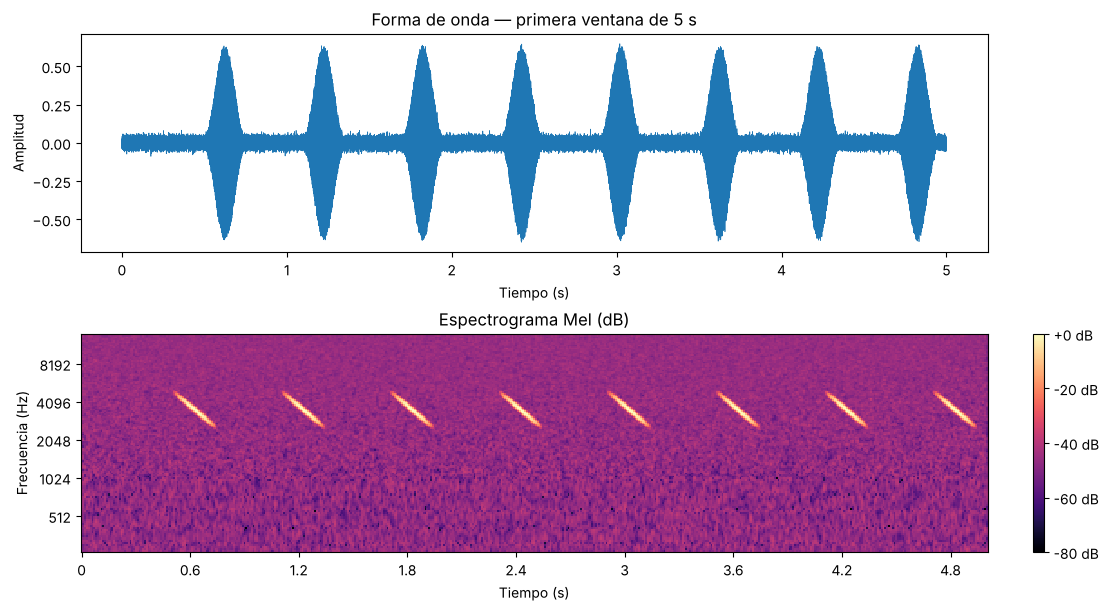

In [3]:
ventanas = segment_signal(senal, cfg.segment_samples, cfg.hop_samples)
espectro = mel_spectrogram(ventanas[0], cfg)

fig, ejes = plt.subplots(2, 1, figsize=(11, 6), constrained_layout=True)
t = np.arange(len(ventanas[0])) / sr
ejes[0].plot(t, ventanas[0], linewidth=0.5)
ejes[0].set(title="Forma de onda — primera ventana de 5 s", xlabel="Tiempo (s)", ylabel="Amplitud")
img = librosa.display.specshow(
    espectro, sr=sr, hop_length=cfg.hop_length, x_axis="time", y_axis="mel",
    fmin=cfg.fmin, fmax=cfg.fmax, ax=ejes[1], cmap="magma",
)
ejes[1].set(title="Espectrograma Mel (dB)", xlabel="Tiempo (s)", ylabel="Frecuencia (Hz)")
fig.colorbar(img, ax=ejes[1], format="%+2.0f dB")
plt.show()

## 2. Dimensiones que recibe el modelo

Cada grabación se convierte en un arreglo `(n_ventanas, n_mels, n_frames)`. Con la configuración por defecto, una ventana de 5 s produce un espectrograma de 128 × 501.

In [4]:
caracteristicas = audio_to_features(senal, cfg)
print(f"Ventanas generadas: {len(ventanas)} (5 s cada una, 50 % de solapamiento)")
print(f"Tensor de entrada por grabación: {caracteristicas.shape}")
print(f"Media ≈ {caracteristicas.mean():.3f} | desviación ≈ {caracteristicas.std():.3f} (estandarizado)")

Ventanas generadas: 4 (5 s cada una, 50 % de solapamiento)
Tensor de entrada por grabación: (4, 128, 501)
Media ≈ -0.000 | desviación ≈ 1.000 (estandarizado)


## 3. Plantilla de EDA de metadatos (se completa en la Entrega 2)

Después de ejecutar `python -m src.main download --species ...`, los metadatos quedan en `data/metadata/xeno_canto.csv`. Las preguntas guía del análisis exploratorio son:

- ¿Cuántas grabaciones hay por especie? (desbalance de clases)
- ¿Cómo se distribuyen la calidad (A–E), la duración y el tipo de vocalización (canto/llamado)?
- ¿Qué licencias tienen las grabaciones y quiénes son sus autores?
- ¿Desde qué regiones de Colombia se grabaron?

In [5]:
ruta_meta = ROOT / "data" / "metadata" / "xeno_canto.csv"

if ruta_meta.exists():
    meta = pd.read_csv(ruta_meta)
    display(meta.head())
    conteo = meta["species"].value_counts()
    ax = conteo.sort_values().plot.barh(figsize=(8, max(3, 0.3 * len(conteo))))
    ax.set(title="Grabaciones por especie", xlabel="Número de grabaciones")
    plt.show()
    if "q" in meta.columns:
        display(meta["q"].value_counts().sort_index().rename("grabaciones por calidad"))
    if "lic" in meta.columns:
        display(meta["lic"].value_counts().rename("grabaciones por licencia"))
else:
    print("Aún no hay metadatos descargados.")
    print('Ejecute: python -m src.main download --species "Turdus fuscater" --max-per-species 30')

Aún no hay metadatos descargados.
Ejecute: python -m src.main download --species "Turdus fuscater" --max-per-species 30


## Próximos pasos

1. Definir la lista de especies objetivo (criterios en `docs/reporte_entrega_1.md`, sección VI).
2. Descargar grabaciones y metadatos; completar el EDA de la sección 3.
3. Generar las ventanas (`python -m src.main preprocess`) y entrenar el modelo base (Entrega 2).